In [ ]:
#import all required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
import lightgbm as lgb
from sklearn.neighbors import KNeighborsRegressor
import xgboost as xgb

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error



In [ ]:
data = pd.read_csv('/content/Dataset.csv')
data.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   instant     17379 non-null  int64 
 1   dteday      17379 non-null  object
 2   season      17379 non-null  object
 3   yr          17379 non-null  object
 4   mnth        17379 non-null  object
 5   hr          17379 non-null  int64 
 6   holiday     17379 non-null  object
 7   weekday     17379 non-null  int64 
 8   workingday  17379 non-null  object
 9   weathersit  17379 non-null  object
 10  temp        17379 non-null  object
 11  atemp       17379 non-null  object
 12  hum         17379 non-null  object
 13  windspeed   17379 non-null  object
 14  casual      17379 non-null  object
 15  registered  17379 non-null  object
 16  cnt         17379 non-null  int64 
dtypes: int64(4), object(13)
memory usage: 2.3+ MB


In [ ]:
data.describe()

,instant,hr,weekday,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000
mean,8690.0000,11.546752,3.003683,189.463088
std,5017.0295,6.914405,2.005771,181.387599
min,1.0000,0.000000,0.000000,1.000000
25%,4345.5000,6.000000,1.000000,40.000000
50%,8690.0000,12.000000,3.000000,142.000000
75%,13034.5000,18.000000,5.000000,281.000000
max,17379.0000,23.000000,6.000000,977.000000


In [ ]:
data.skew(numeric_only=True)

,0
instant,0.000000
hr,-0.010680
weekday,-0.002998
cnt,1.277412


In [ ]:
data.kurt(numeric_only=True)

,0
instant,-1.200000
hr,-1.198021
weekday,-1.255997
cnt,1.417203


In [ ]:
data.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [ ]:
data.replace('?', np.nan, inplace=True)

In [ ]:
data.isnull().sum()

,0
instant,0
dteday,0
season,6
yr,1
mnth,1
hr,0
holiday,1
weekday,0
workingday,5
weathersit,4


In [ ]:
data.duplicated().sum()

np.int64(0)

In [ ]:
data = data.drop_duplicates()
data.head(20)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,NaN,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1
5,6,01-01-2011,springer,2011,1,5,No,6,No work,Mist,0.24,0.2576,0.75,0.0896,0,1,1
6,7,01-01-2011,springer,2011,1,6,No,6,No work,NaN,0.22,0.2727,0.8,0,2,0,2
7,8,01-01-2011,springer,2011,1,7,No,6,No work,Clear,0.2,0.2576,0.86,0,1,2,3
8,9,01-01-2011,springer,2011,1,8,No,6,No work,Clear,0.24,0.2879,0.75,0,1,7,8
9,10,01-01-2011,springer,2011,1,9,No,6,No work,Clear,NaN,0.3485,0.76,0,8,6,14


In [ ]:
# Work on a copy
df_check = data.copy()

# Replace invalid placeholders with NaN
df_check = df_check.replace(
    ['?', '', 'NA', 'N/A', 'null', 'None'],
    np.nan
)

# Convert numeric columns
numeric_cols = [
    'instant', 'yr', 'mnth', 'hr', 'weekday',
    'temp', 'atemp', 'hum', 'windspeed',
    'casual', 'registered', 'cnt'
]

for col in numeric_cols:
    df_check[col] = pd.to_numeric(
        df_check[col], errors='coerce'
    )

# Convert date
df_check['dteday'] = pd.to_datetime(
    df_check['dteday'],
    format='%d-%m-%Y',
    errors='coerce'
)

# Define valid values for each column
invalid_conditions = {
    'instant': df_check['instant'] <= 0,
    'dteday': df_check['dteday'].isna(),
    'season': ~df_check['season'].isin(
        ['springer', 'summer', 'fall', 'winter']
    ),
    'yr': ~df_check['yr'].isin([2011, 2012]),
    'mnth': ~df_check['mnth'].between(1, 12),
    'hr': ~df_check['hr'].between(0, 23),
    'holiday': ~df_check['holiday'].isin(['Yes', 'No']),
    'weekday': ~df_check['weekday'].between(0, 6),
    'workingday': ~df_check['workingday'].isin(
        ['Working Day', 'No work']
    ),
    'weathersit': ~df_check['weathersit'].isin(
        ['Clear', 'Mist', 'Light Snow', 'Heavy Rain']
    ),
    'temp': ~df_check['temp'].between(0, 1),
    'atemp': ~df_check['atemp'].between(0, 1),
    'hum': ~df_check['hum'].between(0, 1),
    'windspeed': ~df_check['windspeed'].between(0, 1),
    'casual': df_check['casual'] < 0,
    'registered': df_check['registered'] < 0,
    'cnt': df_check['cnt'] < 0
}

# Count invalid records for every column
invalid_summary = pd.DataFrame({
    col: {'Invalid Records': condition.sum()}
    for col, condition in invalid_conditions.items()
}).T

# Include missing/invalid placeholder values
invalid_summary['Missing Values'] = df_check.isna().sum()

print(invalid_summary)

            Invalid Records  Missing Values
instant                   0               0
dteday                    0               0
season                    6               6
yr                        1               1
mnth                      1               1
hr                        0               0
holiday                   1               1
weekday                   0               0
workingday                5               5
weathersit                4               4
temp                     11              11
atemp                     6               6
hum                       6               6
windspeed                 5               5
casual                    0               1
registered                0               1
cnt                       0               0


In [ ]:
# Check mismatched rental counts
invalid_count = df_check[
    df_check['cnt'] != (
        df_check['casual'] + df_check['registered']
    )
]

print("Mismatched rental records:", len(invalid_count))

Mismatched rental records: 1


In [ ]:
for col in data.columns:

    if data[col].dtype == 'object':
        # Categorical column: fill with mode
        data[col] = data[col].fillna(data[col].mode()[0])

    else:
        # Numerical column: fill with median
        data[col] = data[col].fillna(data[col].median())

print(data)

       instant      dteday    season    yr mnth  hr holiday  weekday  \
0            1  01-01-2011  springer  2011    1   0      No        6   
1            2  01-01-2011  springer  2011    1   1      No        6   
2            3  01-01-2011  springer  2011    1   2      No        6   
3            4  01-01-2011  springer  2011    1   3      No        6   
4            5  01-01-2011  springer  2011    1   4      No        6   
...        ...         ...       ...   ...  ...  ..     ...      ...   
17374    17375  31-12-2012  springer  2012   12  19      No        1   
17375    17376  31-12-2012  springer  2012   12  20      No        1   
17376    17377  31-12-2012  springer  2012   12  21      No        1   
17377    17378  31-12-2012  springer  2012   12  22      No        1   
17378    17379  31-12-2012  springer  2012   12  23      No        1   

        workingday weathersit  temp   atemp   hum windspeed casual registered  \
0          No work      Clear  0.24  0.2879  0.81     

In [ ]:
data.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


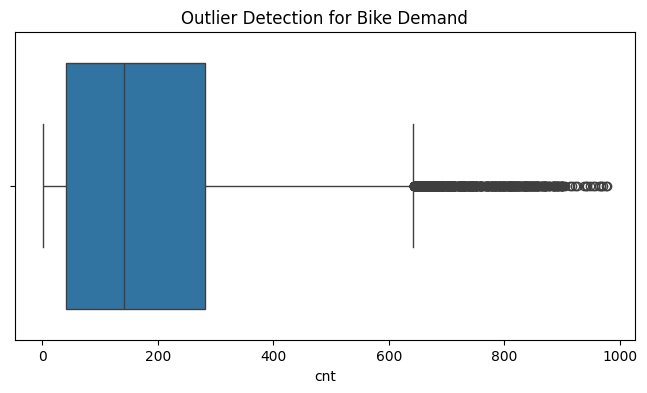

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=data['cnt'])

plt.title('Outlier Detection for Bike Demand')
plt.show()

In [ ]:


# Ensure the column is numeric before computing quantiles
data['cnt'] = pd.to_numeric(data['cnt'], errors='coerce')

Q1 = data['cnt'].quantile(0.25)
Q3 = data['cnt'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[(data['cnt'] < lower_bound) | (data['cnt'] > upper_bound)]
outliers

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
5536,5537,23-08-2011,fall,2011,8,14,No,2,Working Day,Clear,0.72,0.6515,0.3,0.0896,149,502,651
10358,10359,12-03-2012,springer,2012,3,17,No,1,Working Day,Mist,0.62,0.6212,0.38,0.4179,87,557,644
10359,10360,12-03-2012,springer,2012,3,18,No,1,Working Day,Mist,0.6,0.6212,0.43,0.194,89,623,712
10382,10383,13-03-2012,springer,2012,3,17,No,2,Working Day,Clear,0.7,0.6364,0.37,0.1045,62,614,676
10383,10384,13-03-2012,springer,2012,3,18,No,2,Working Day,Clear,0.7,0.6364,0.34,0.2985,96,638,734
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16885,16886,11-12-2012,winter,2012,12,8,No,2,Working Day,Mist,0.34,0.303,0.61,0.2985,16,708,724
16909,16910,12-12-2012,winter,2012,12,8,No,3,Working Day,Mist,0.26,0.2576,0.65,0.1642,18,670,688
16933,16934,13-12-2012,winter,2012,12,8,No,4,Working Day,Clear,0.24,0.2273,0.6,0.194,24,655,679
17053,17054,18-12-2012,winter,2012,12,8,No,2,Working Day,Clear,0.38,0.3939,0.94,0,10,652,662


In [ ]:
# Filter out the outliers to keep only data within the non-outlier range
data_cleaned = data[(data['cnt'] >= lower_bound) & (data['cnt'] <= upper_bound)]

print(f"Original dataset shape: {data.shape}")
print(f"Cleaned dataset shape: {data_cleaned.shape}")
print(f"Removed {data.shape[0] - data_cleaned.shape[0]} outliers.")

# Assign back to data variable
data = data_cleaned


Original dataset shape: (17379, 17)
Cleaned dataset shape: (16874, 17)
Removed 505 outliers.


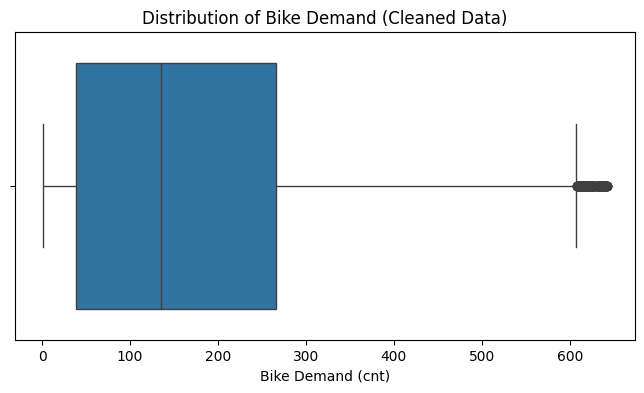

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=data['cnt'])
plt.title('Distribution of Bike Demand (Cleaned Data)')
plt.xlabel('Bike Demand (cnt)')
plt.show()

# 2.Data visualisation

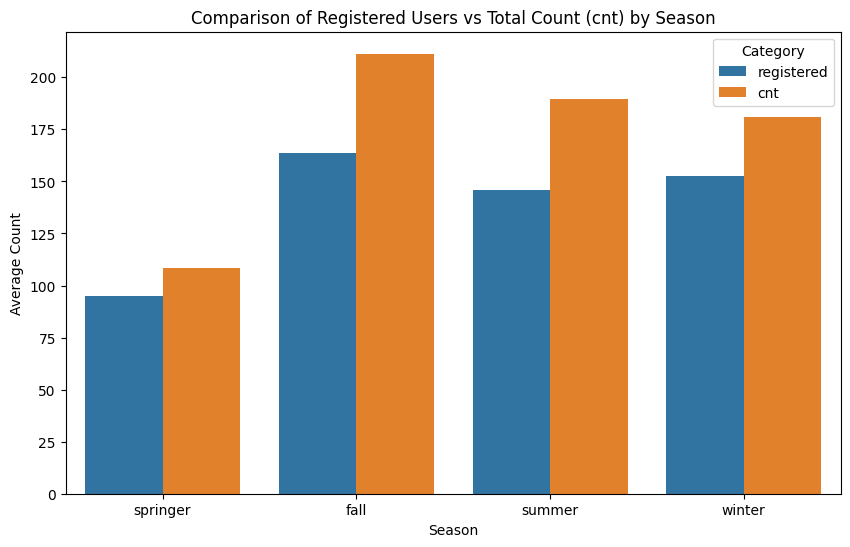

In [ ]:

# Ensure registered and cnt are numeric types for plotting
data['registered'] = pd.to_numeric(data['registered'])
data['cnt'] = pd.to_numeric(data['cnt'])

# Melt the dataset to have 'registered' and 'cnt' in a single column for side-by-side plotting
data_melted = data.melt(id_vars=['season'], value_vars=['registered', 'cnt'],
                        var_name='Type', value_name='Count')

# Create the barplot
plt.figure(figsize=(10, 6))
sns.barplot(data=data_melted, x='season', y='Count', hue='Type', errorbar=None)

plt.title('Comparison of Registered Users vs Total Count (cnt) by Season')
plt.xlabel('Season')
plt.ylabel('Average Count')
plt.legend(title='Category')
plt.show()

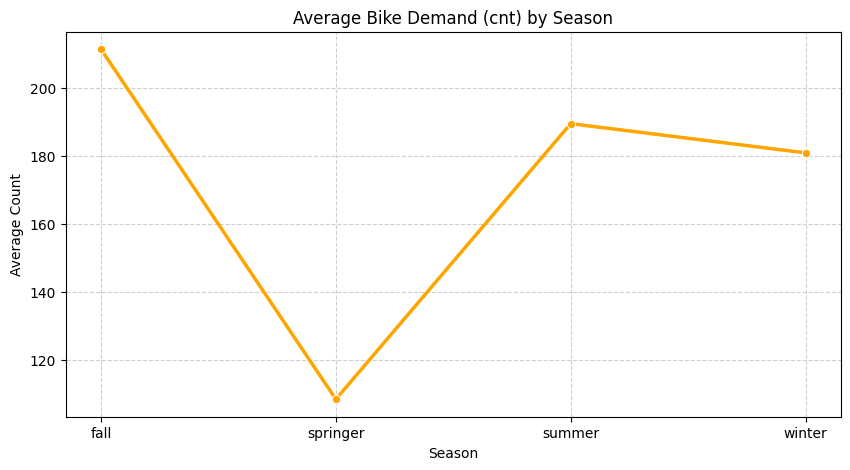

In [ ]:
# Calculate average count for each season
seasonal_demand = data.groupby('season')['cnt'].mean().reset_index()

# Create the line chart
plt.figure(figsize=(10, 5))
sns.lineplot(data=seasonal_demand, x='season', y='cnt', marker='o', linewidth=2.5, color='orange')

plt.title('Average Bike Demand (cnt) by Season')
plt.xlabel('Season')
plt.ylabel('Average Count')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

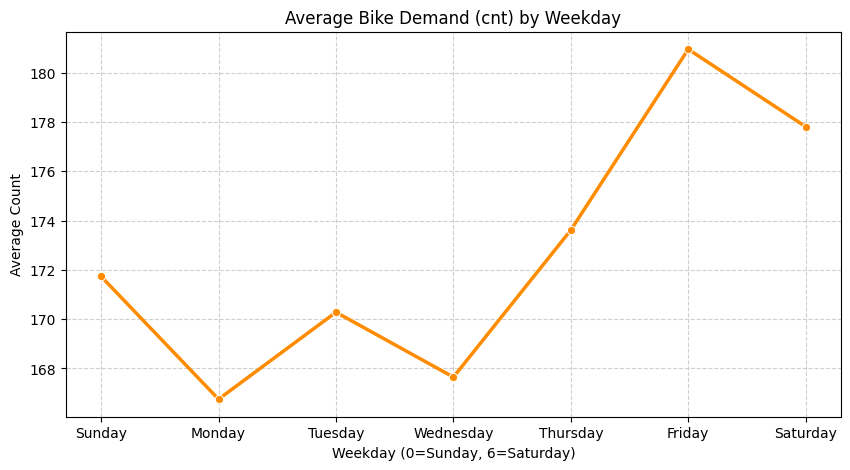

In [ ]:
# Calculate average bike demand (cnt) for each weekday
weekday_demand = data.groupby('weekday')['cnt'].mean().reset_index()

# Create the line chart
plt.figure(figsize=(10, 5))
sns.lineplot(data=weekday_demand, x='weekday', y='cnt', marker='o', linewidth=2.5, color='darkorange')

plt.title('Average Bike Demand (cnt) by Weekday')
plt.xlabel('Weekday (0=Sunday, 6=Saturday)')
plt.ylabel('Average Count')
plt.xticks(range(7), ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

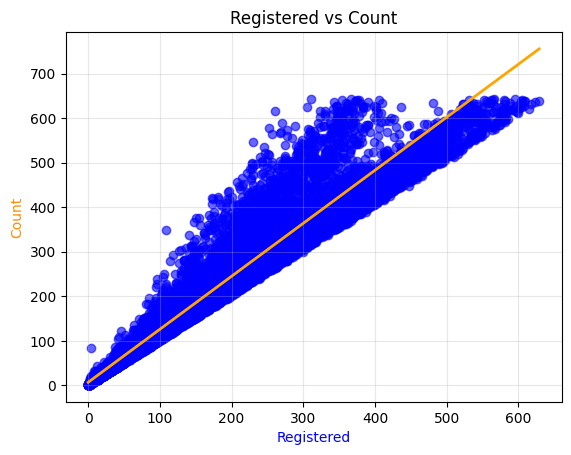

In [ ]:
sns.regplot(
    data=data,
    x='registered',
    y='cnt',
    ci=None,
    scatter_kws={'color': 'blue', 'alpha': 0.6},
    line_kws={'color': 'orange', 'linewidth': 2}
)

plt.xlabel('Registered', color='blue')
plt.ylabel('Count', color='darkorange')
plt.title('Registered vs Count')
plt.grid(True, alpha=0.3)
plt.show()

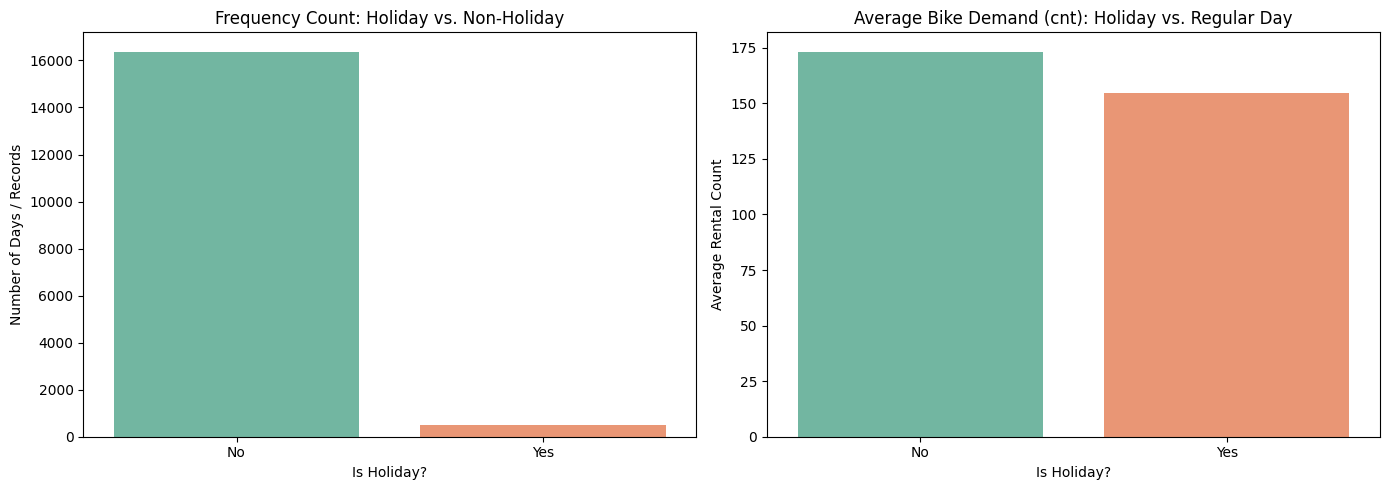

In [ ]:
# Set up a side-by-side subplot to compare frequency of holidays and their total bike demand
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Count plot showing the frequency of Yes/No for holidays in the dataset
sns.countplot(data=data, x='holiday', hue='holiday', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Frequency Count: Holiday vs. Non-Holiday')
axes[0].set_xlabel('Is Holiday?')
axes[0].set_ylabel('Number of Days / Records')

# 2. Bar plot showing the average bike demand (cnt) on holiday vs non-holiday
sns.barplot(data=data, x='holiday', y='cnt', hue='holiday', palette='Set2', errorbar=None, legend=False, ax=axes[1])
axes[1].set_title('Average Bike Demand (cnt): Holiday vs. Regular Day')
axes[1].set_xlabel('Is Holiday?')
axes[1].set_ylabel('Average Rental Count')

plt.tight_layout()
plt.show()

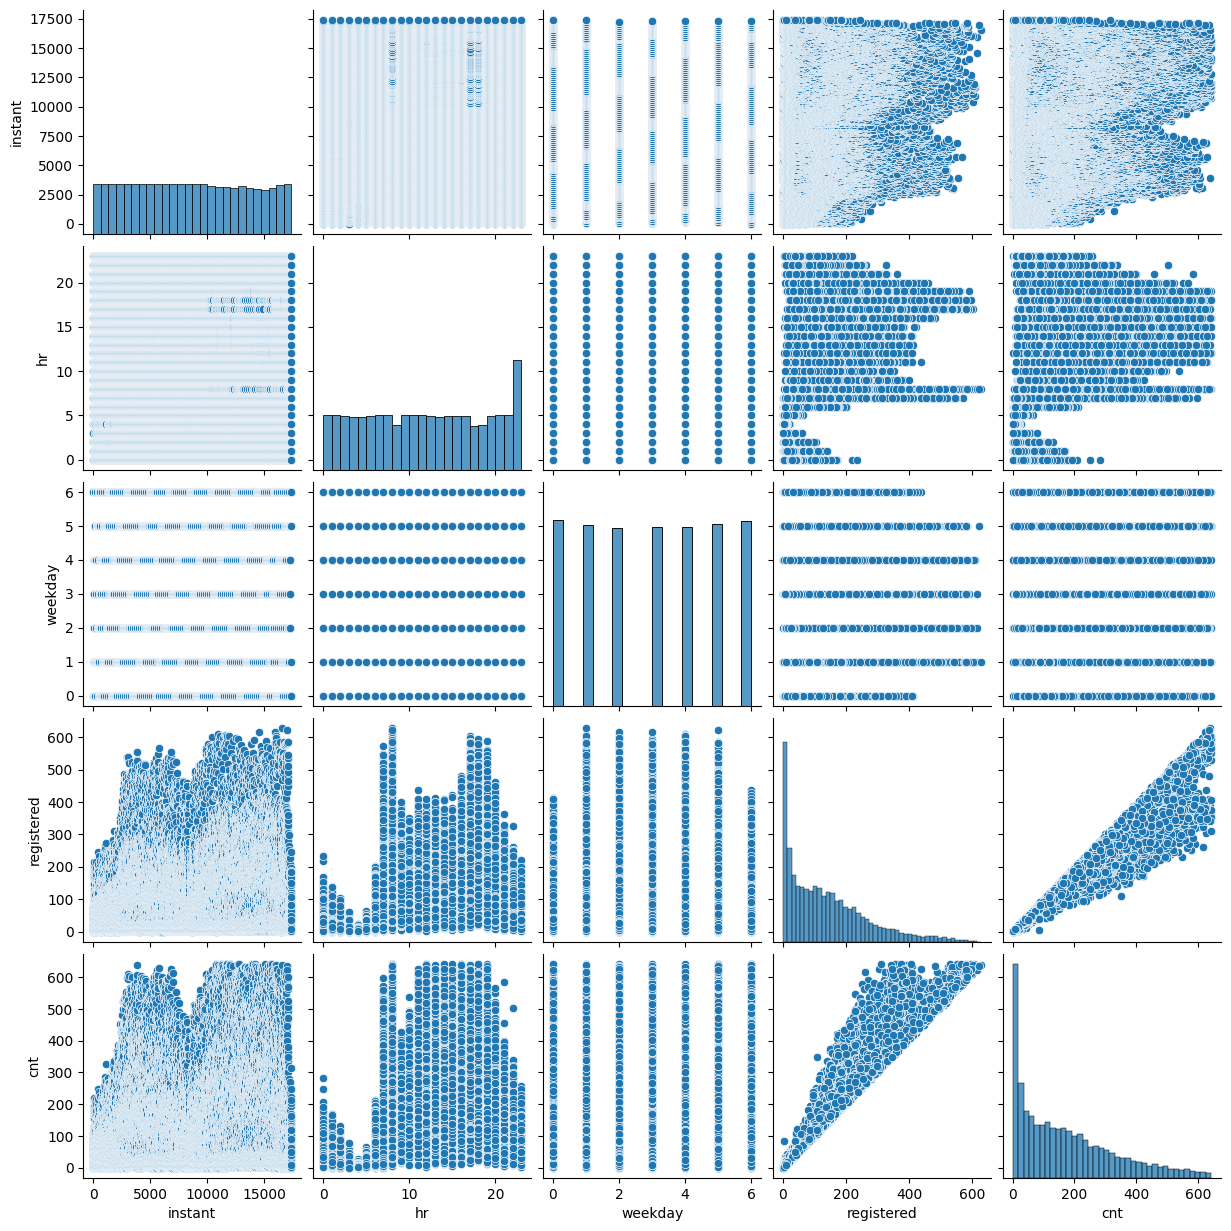

In [ ]:
sns.pairplot(data)
plt.show()

In [ ]:
# Calculate the exact average bike demand (cnt) for holidays and regular days
holiday_demand = data.groupby('holiday')['cnt'].mean().reset_index()
display(holiday_demand)

,holiday,cnt
0,No,173.257450
1,Yes,154.712851


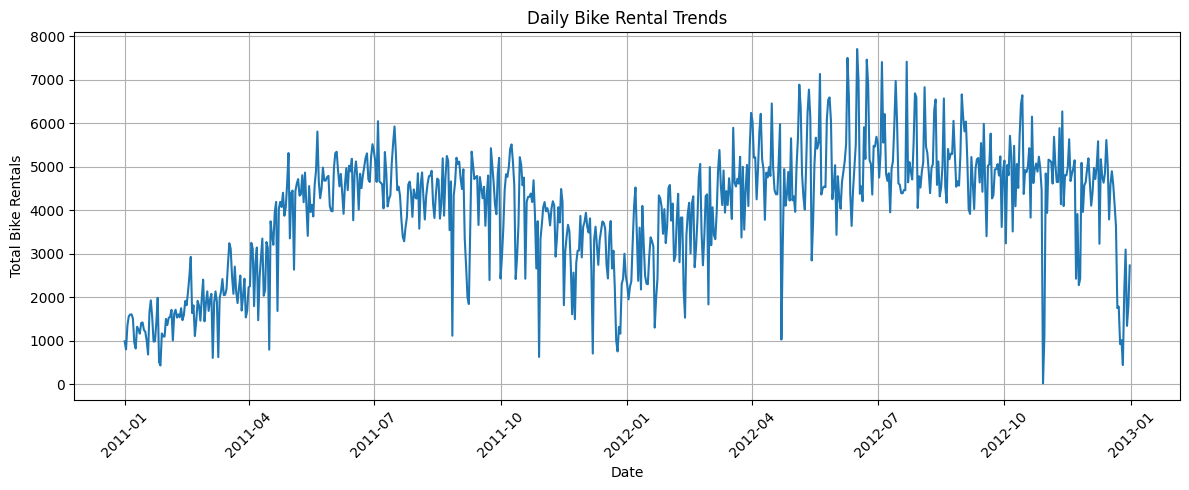

In [ ]:
# Convert date column to datetime
data['dteday'] = pd.to_datetime(
    data['dteday'],
    dayfirst=True,
    errors='coerce'
)

# Group data by date
daily_data = data.groupby('dteday')['cnt'].sum()

# Plot time series
plt.figure(figsize=(12, 5))
plt.plot(daily_data.index, daily_data.values)

plt.title('Daily Bike Rental Trends')
plt.xlabel('Date')
plt.ylabel('Total Bike Rentals')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

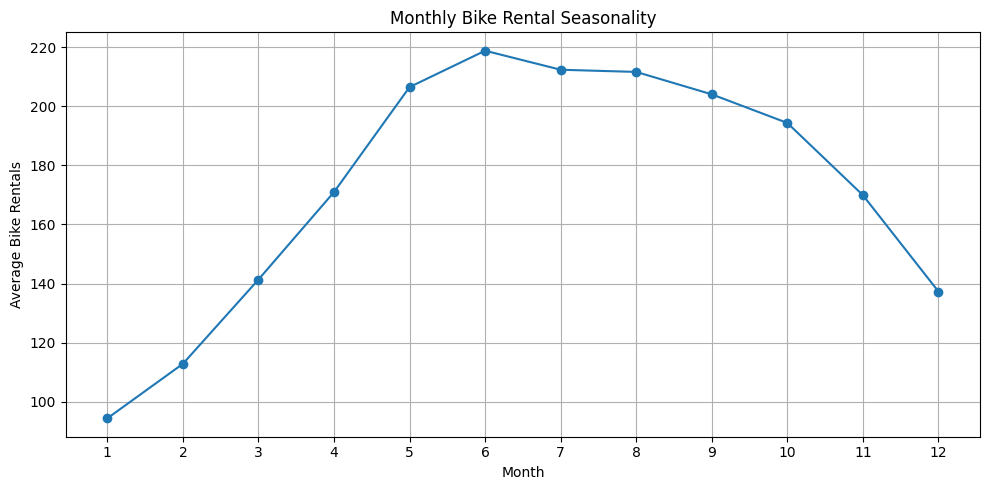

In [ ]:
# Extract month from date
data['month'] = data['dteday'].dt.month

# Calculate average rentals for each month
monthly_data = data.groupby('month')['cnt'].mean()

# Plot monthly seasonality
plt.figure(figsize=(10, 5))
plt.plot(monthly_data.index, monthly_data.values, marker='o')

plt.title('Monthly Bike Rental Seasonality')
plt.xlabel('Month')
plt.ylabel('Average Bike Rentals')
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

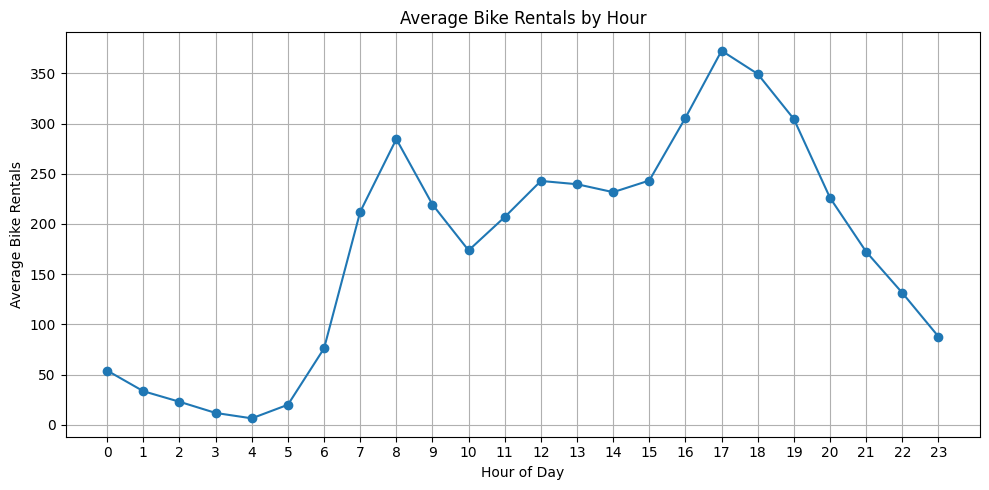

In [ ]:
hourly_data = data.groupby('hr')['cnt'].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_data.index, hourly_data.values, marker='o')

plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Bike Rentals')
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

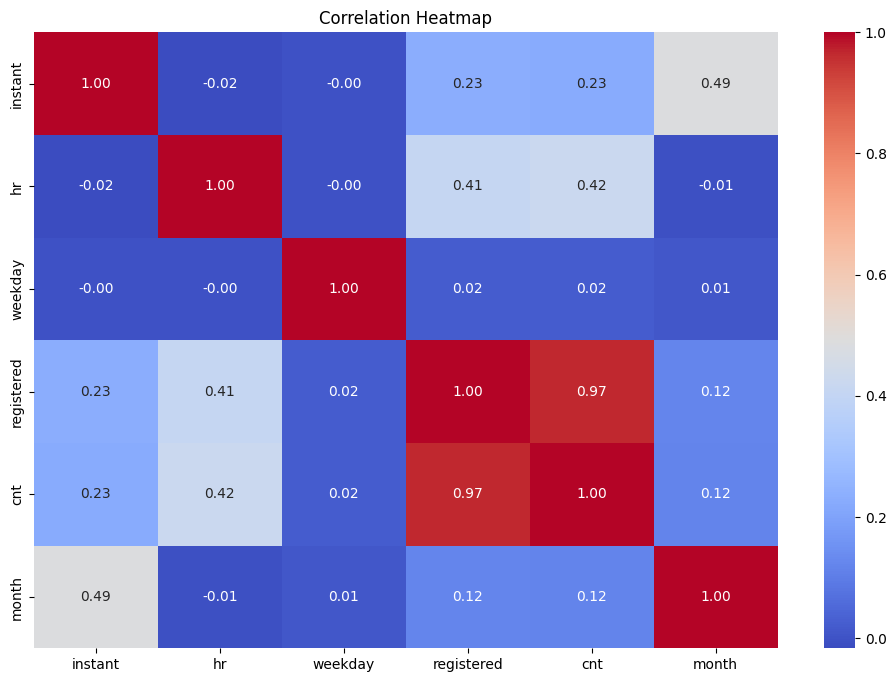

In [ ]:
# Calculate correlation
corr = data.select_dtypes(include='number').corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

# 3. **Feature** **engineering**

In [ ]:
# Work on a copy of your cleaned dataset
data_fe = data.copy()

# Convert date column to datetime
data_fe['dteday'] = pd.to_datetime(data_fe['dteday'])

# 1. Morning commute: Weekdays, non-holidays, 7 AM to 9 AM
data_fe['morning_commute'] = (
    (data_fe['workingday'] == 1) &
    (data_fe['hr'].between(7, 9))
).astype(int)

# 2. Evening commute: Weekdays, non-holidays, 4 PM to 7 PM
data_fe['evening_commute'] = (
    (data_fe['workingday'] == 1) &
    (data_fe['hr'].between(16, 19))
).astype(int)


data_fe[['morning_commute', 'evening_commute']].head()

,morning_commute,evening_commute
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0


In [ ]:
# Extract weekday name from date
data_fe['weekday_name'] = data_fe['dteday'].dt.day_name()

data_fe[['dteday', 'weekday_name']].head()

,dteday,weekday_name
0,2011-01-01,Saturday
1,2011-01-01,Saturday
2,2011-01-01,Saturday
3,2011-01-01,Saturday
4,2011-01-01,Saturday


In [ ]:
data_fe.head(100)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,atemp,hum,windspeed,casual,registered,cnt,month,morning_commute,evening_commute,weekday_name
0,1,2011-01-01,springer,2011,1,0,No,6,No work,Clear,...,0.2879,0.81,0,3,13,16,1,0,0,Saturday
1,2,2011-01-01,springer,2011,1,1,No,6,No work,Clear,...,0.2727,0.8,0,8,32,40,1,0,0,Saturday
2,3,2011-01-01,springer,2011,1,2,No,6,No work,Clear,...,0.2727,0.88,0,5,27,32,1,0,0,Saturday
3,4,2011-01-01,springer,2011,1,3,No,6,No work,Clear,...,0.2879,0.75,0,3,10,13,1,0,0,Saturday
4,5,2011-01-01,springer,2011,1,4,No,6,No work,Clear,...,0.2879,0.75,0,0,1,1,1,0,0,Saturday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,2011-01-05,springer,2011,1,4,No,3,Working Day,Clear,...,0.2273,0.48,0.2239,0,2,2,1,0,0,Wednesday
96,97,2011-01-05,springer,2011,1,5,No,3,Working Day,Clear,...,0.2273,0.47,0.1642,0,3,3,1,0,0,Wednesday
97,98,2011-01-05,springer,2011,1,6,No,3,Working Day,Clear,...,0.197,0.47,0.2239,0,33,33,1,0,0,Wednesday
98,99,2011-01-05,springer,2011,1,7,No,3,Working Day,Clear,...,0.1818,0.43,0.194,1,87,88,1,0,0,Wednesday


In [ ]:
# Ensure dteday is in datetime format
data_fe['dteday'] = pd.to_datetime(data_fe['dteday'])

# Extract day of the year (pandas automatically handles leap years like 2012 correctly)
data_fe['day_of_year'] = data_fe['dteday'].dt.dayofyear

# Display the date and corresponding day_of_year to verify
display(data_fe[['dteday', 'day_of_year']].drop_duplicates().head())

# Check a known date in a leap year (e.g., Dec 31, 2012 should be 366)
display(data_fe[data_fe['dteday'] == '2012-12-31'][['dteday', 'day_of_year']].head(1))

,dteday,day_of_year
0,2011-01-01,1
24,2011-01-02,2
47,2011-01-03,3
69,2011-01-04,4
92,2011-01-05,5


,dteday,day_of_year
17355,2012-12-31,366


In [ ]:
# Extract weekend feature (1 for Sunday only, 0 otherwise)
data_fe['is_weekend'] = data_fe['dteday'].dt.dayofweek.isin([6]).astype(int)

# Verify by viewing some sample dates along with the weekday name and is_weekend flag
display(data_fe[['dteday', 'weekday_name', 'is_weekend']].drop_duplicates().head(10))

,dteday,weekday_name,is_weekend
0,2011-01-01,Saturday,0
24,2011-01-02,Sunday,1
47,2011-01-03,Monday,0
69,2011-01-04,Tuesday,0
92,2011-01-05,Wednesday,0
115,2011-01-06,Thursday,0
138,2011-01-07,Friday,0
161,2011-01-08,Saturday,0
185,2011-01-09,Sunday,1
209,2011-01-10,Monday,0


In [ ]:
data_fe.head(100)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,windspeed,casual,registered,cnt,month,morning_commute,evening_commute,weekday_name,day_of_year,is_weekend
0,1,2011-01-01,springer,2011,1,0,No,6,No work,Clear,...,0,3,13,16,1,0,0,Saturday,1,0
1,2,2011-01-01,springer,2011,1,1,No,6,No work,Clear,...,0,8,32,40,1,0,0,Saturday,1,0
2,3,2011-01-01,springer,2011,1,2,No,6,No work,Clear,...,0,5,27,32,1,0,0,Saturday,1,0
3,4,2011-01-01,springer,2011,1,3,No,6,No work,Clear,...,0,3,10,13,1,0,0,Saturday,1,0
4,5,2011-01-01,springer,2011,1,4,No,6,No work,Clear,...,0,0,1,1,1,0,0,Saturday,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,2011-01-05,springer,2011,1,4,No,3,Working Day,Clear,...,0.2239,0,2,2,1,0,0,Wednesday,5,0
96,97,2011-01-05,springer,2011,1,5,No,3,Working Day,Clear,...,0.1642,0,3,3,1,0,0,Wednesday,5,0
97,98,2011-01-05,springer,2011,1,6,No,3,Working Day,Clear,...,0.2239,0,33,33,1,0,0,Wednesday,5,0
98,99,2011-01-05,springer,2011,1,7,No,3,Working Day,Clear,...,0.194,1,87,88,1,0,0,Wednesday,5,0


In [ ]:
# Check created features
print("Dataset Shape:", data_fe.shape)

print("\nCommute and Time Features:")
print(
    data_fe[
        ['morning_commute',
         'evening_commute',]
    ].head()
)

print("\nMissing Values:")
print(data_fe.isnull().sum().sum())

print("\nAll Columns:")
print(data_fe.columns.tolist())

Dataset Shape: (16874, 23)

Commute and Time Features:
   morning_commute  evening_commute
0                0                0
1                0                0
2                0                0
3                0                0
4                0                0

Missing Values:
0

All Columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'month', 'morning_commute', 'evening_commute', 'weekday_name', 'day_of_year', 'is_weekend']


#### Handle Catagorical values

In [ ]:


# 1. Ensure existing numerical columns in 'data' are numeric types (not object/string)
num_cols_to_fix = ['yr', 'mnth', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
for col in num_cols_to_fix:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# 2. Label Encoding for binary categorical columns
le = LabelEncoder()
binary_Archive_cols = ['holiday', 'workingday']
for col in binary_Archive_cols:
    data[col] = le.fit_transform(data[col])

# 3. One-Hot Encoding for multi-class categorical columns
categorical_cols = ['season', 'weathersit']
data = pd.get_dummies(data, columns=categorical_cols, drop_first=True, dtype=int)

data.head()

,instant,dteday,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,...,casual,registered,cnt,month,season_springer,season_summer,season_winter,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist
0,1,2011-01-01,2011,1,0,0,6,0,0.24,0.2879,...,3,13,16,1,1,0,0,0,0,0
1,2,2011-01-01,2011,1,1,0,6,0,0.22,0.2727,...,8,32,40,1,1,0,0,0,0,0
2,3,2011-01-01,2011,1,2,0,6,0,0.22,0.2727,...,5,27,32,1,1,0,0,0,0,0
3,4,2011-01-01,2011,1,3,0,6,0,0.24,0.2879,...,3,10,13,1,1,0,0,0,0,0
4,5,2011-01-01,2011,1,4,0,6,0,0.24,0.2879,...,0,1,1,1,1,0,0,0,0,0


#### Numerical features

In [ ]:

# Define the numerical features to scale
numerical_features = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'hr', 'mnth', 'weekday']

# Initialize the scaler
scaler = StandardScaler()

# Scale the numerical features in place
data[numerical_features] = scaler.fit_transform(data[numerical_features])

# Verify the transformed dataset
data.head()

,instant,dteday,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,...,casual,registered,cnt,month,season_springer,season_summer,season_winter,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist
0,1,2011-01-01,2011,-1.592347,-1.645821,0,1.491436,0,-1.314441,-1.071892,...,-0.662736,-1.001879,16,1,1,0,0,0,0,0
1,2,2011-01-01,2011,-1.592347,-1.502182,0,1.491436,0,-1.418399,-1.160344,...,-0.553794,-0.851147,40,1,1,0,0,0,0,0
2,3,2011-01-01,2011,-1.592347,-1.358544,0,1.491436,0,-1.418399,-1.160344,...,-0.619160,-0.890813,32,1,1,0,0,0,0,0
3,4,2011-01-01,2011,-1.592347,-1.214906,0,1.491436,0,-1.314441,-1.071892,...,-0.662736,-1.025678,13,1,1,0,0,0,0,0
4,5,2011-01-01,2011,-1.592347,-1.071268,0,1.491436,0,-1.314441,-1.071892,...,-0.728102,-1.097078,1,1,1,0,0,0,0,0


**3.Model Building**

Import required libraries

Understand the dataset

In [ ]:
# Display dataset information

print("Dataset Shape:", data.shape)

print("\nColumn Names:")
print(data.columns.tolist())

print("\nDataset Information:")
data.info()

print("\nFirst Five Records:")
display(data.head())

Dataset Shape: (16874, 22)

Column Names:
['instant', 'dteday', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'month', 'season_springer', 'season_summer', 'season_winter', 'weathersit_Heavy Rain', 'weathersit_Light Snow', 'weathersit_Mist']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 16874 entries, 0 to 17378
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   instant                16874 non-null  int64         
 1   dteday                 16874 non-null  datetime64[ns]
 2   yr                     16874 non-null  int64         
 3   mnth                   16874 non-null  float64       
 4   hr                     16874 non-null  float64       
 5   holiday                16874 non-null  int64         
 6   weekday                16874 non-null  float64       
 7   workingday         

,instant,dteday,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,...,casual,registered,cnt,month,season_springer,season_summer,season_winter,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist
0,1,2011-01-01,2011,-1.592347,-1.645821,0,1.491436,0,-1.314441,-1.071892,...,-0.662736,-1.001879,16,1,1,0,0,0,0,0
1,2,2011-01-01,2011,-1.592347,-1.502182,0,1.491436,0,-1.418399,-1.160344,...,-0.553794,-0.851147,40,1,1,0,0,0,0,0
2,3,2011-01-01,2011,-1.592347,-1.358544,0,1.491436,0,-1.418399,-1.160344,...,-0.619160,-0.890813,32,1,1,0,0,0,0,0
3,4,2011-01-01,2011,-1.592347,-1.214906,0,1.491436,0,-1.314441,-1.071892,...,-0.662736,-1.025678,13,1,1,0,0,0,0,0
4,5,2011-01-01,2011,-1.592347,-1.071268,0,1.491436,0,-1.314441,-1.071892,...,-0.728102,-1.097078,1,1,1,0,0,0,0,0


Clean the dataset

In [ ]:
# Replace question marks with missing values

data = data.replace('?', np.nan)

# Convert numerical columns into numeric format

numeric_columns = [
    'yr', 'mnth', 'hr', 'weekday',
    'temp', 'atemp', 'hum', 'windspeed',
    'casual', 'registered', 'cnt'
]

for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Check missing values

print("Missing Values:")
print(data.isnull().sum())

Missing Values:
instant                  0
dteday                   0
yr                       0
mnth                     0
hr                       0
holiday                  0
weekday                  0
workingday               0
temp                     0
atemp                    0
hum                      0
windspeed                0
casual                   0
registered               0
cnt                      0
month                    0
season_springer          0
season_summer            0
season_winter            0
weathersit_Heavy Rain    0
weathersit_Light Snow    0
weathersit_Mist          0
dtype: int64


Convert date and handle missing values

In [ ]:
# Convert date into proper date format
if 'dteday' in data.columns:
    data['dteday'] = pd.to_datetime(
        data['dteday'],
        errors='coerce'
    )

# Sort records according to date and hour if columns exist
sort_cols = [col for col in ['dteday', 'hr'] if col in data.columns]
if sort_cols:
    data = data.sort_values(by=sort_cols).reset_index(drop=True)

# Remove records where target value is missing
if 'cnt' in data.columns:
    data = data.dropna(subset=['cnt'])

# Fill missing numerical values with median
for col in numeric_columns:
    if col != 'cnt' and col in data.columns:
        data[col] = data[col].fillna(data[col].median())

# Fill missing categorical values with mode (if they still exist as original categorical columns)
categorical_columns = [
    'season', 'holiday', 'workingday', 'weathersit'
]

for col in categorical_columns:
    if col in data.columns:
        data[col] = data[col].fillna(data[col].mode()[0])

print("Data cleaning step completed successfully!")
print("Remaining missing values:", data.isnull().sum().sum())

Data cleaning step completed successfully!
Remaining missing values: 0


Select input and output variables

In [ ]:
# Remove unnecessary columns

model_data = data.drop(
    columns=[
        'instant',
        'dteday',
        'casual',
        'registered'
    ]
)

# Separate input and output variables

X = model_data.drop('cnt', axis=1)

y = model_data['cnt']

print("Input Features:", X.shape)
print("Target Variable:", y.shape)

display(X.head())

Input Features: (16874, 17)
Target Variable: (16874,)


,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,hum,windspeed,month,season_springer,season_summer,season_winter,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist
0,2011,-1.592347,-1.645821,0,1.491436,0,-1.314441,-1.071892,0.931952,-1.547794,1,1,0,0,0,0,0
1,2011,-1.592347,-1.502182,0,1.491436,0,-1.418399,-1.160344,0.880038,-1.547794,1,1,0,0,0,0,0
2,2011,-1.592347,-1.358544,0,1.491436,0,-1.418399,-1.160344,1.295348,-1.547794,1,1,0,0,0,0,0
3,2011,-1.592347,-1.214906,0,1.491436,0,-1.314441,-1.071892,0.620470,-1.547794,1,1,0,0,0,0,0
4,2011,-1.592347,-1.071268,0,1.491436,0,-1.314441,-1.071892,0.620470,-1.547794,1,1,0,0,0,0,0


Convert categorical data into numerical data

In [ ]:
# Convert categorical columns into numerical format

X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

print("Categorical conversion completed!")

display(X.head())

Categorical conversion completed!


,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,hum,windspeed,month,season_springer,season_summer,season_winter,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist
0,2011,-1.592347,-1.645821,0,1.491436,0,-1.314441,-1.071892,0.931952,-1.547794,1,1,0,0,0,0,0
1,2011,-1.592347,-1.502182,0,1.491436,0,-1.418399,-1.160344,0.880038,-1.547794,1,1,0,0,0,0,0
2,2011,-1.592347,-1.358544,0,1.491436,0,-1.418399,-1.160344,1.295348,-1.547794,1,1,0,0,0,0,0
3,2011,-1.592347,-1.214906,0,1.491436,0,-1.314441,-1.071892,0.620470,-1.547794,1,1,0,0,0,0,0
4,2011,-1.592347,-1.071268,0,1.491436,0,-1.314441,-1.071892,0.620470,-1.547794,1,1,0,0,0,0,0


**Model Building**

Split training and testing data

In [ ]:
# Split dataset into training and testing data

split_point = int(len(X) * 0.80)

X_train = X.iloc[:split_point]
X_test = X.iloc[split_point:]

y_train = y.iloc[:split_point]
y_test = y.iloc[split_point:]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Data splitting completed!")

Training Data: (13499, 17)
Testing Data: (3375, 17)
Data splitting completed!


# Model 1:Decision Tree Regression

In [ ]:
# Create Decision Tree model

dt_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

# Train the model

dt_model.fit(X_train, y_train)

# Predict bike rental demand

dt_predictions = dt_model.predict(X_test)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


# Model 2:Random Forest Regression

In [ ]:
# Create Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train the model

rf_model.fit(X_train, y_train)

# Predict bike rental demand

rf_predictions = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


# Model 3:Gradient Boosting Regression

In [ ]:
# Create Gradient Boosting model

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model

gb_model.fit(X_train, y_train)

# Predict bike rental demand

gb_predictions = gb_model.predict(X_test)

print("Gradient Boosting Model Trained Successfully!")

Gradient Boosting Model Trained Successfully!


# Model 4:LightGBM

In [ ]:
# --- LightGBM Model ---


# Initialize and train LightGBM Regressor
lgb_model = lgb.LGBMRegressor(n_estimators=100, random_state=42)
lgb_model.fit(X_train, y_train)

# Make predictions
lgb_preds = lgb_model.predict(X_test)

# Evaluate LightGBM
print("LightGBM Performance:")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, lgb_preds)):.2f}")
print(f"MAE:  {mean_absolute_error(y_test, lgb_preds):.2f}")
print(f"R2 Score: {r2_score(y_test, lgb_preds):.4f}")

print("LightGBM Model Trained Successfully!")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007227 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 302
[LightGBM] [Info] Number of data points in the train set: 13499, number of used features: 16
[LightGBM] [Info] Start training from score 163.399289
LightGBM Performance:
RMSE: 59.27
MAE:  38.81
R2 Score: 0.8808
LightGBM Model Trained Successfully!


# Model 5:KNN

In [ ]:
# --- K-Nearest Neighbors (KNN) Model ---

# Initialize and train KNN Regressor
knn_model = KNeighborsRegressor(n_neighbors=5, weights='distance')
knn_model.fit(X_train, y_train)

# Make predictions
knn_preds = knn_model.predict(X_test)

# Evaluate KNN
print("KNN Performance:")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, knn_preds)):.2f}")
print(f"MAE:  {mean_absolute_error(y_test, knn_preds):.2f}")
print(f"R2 Score: {r2_score(y_test, knn_preds):.4f}")

print("KNN Trained Successfully!")

KNN Performance:
RMSE: 121.61
MAE:  84.93
R2 Score: 0.4983
KNN Trained Successfully!


# Model 6:XGBoost

In [ ]:
# --- XGBoost Model ---
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np

# Initialize and train XGBoost Regressor
xgb_model = xgb.XGBRegressor(n_estimators=100, random_state=42)
xgb_model.fit(X_train, y_train)

# Make predictions
xgb_preds = xgb_model.predict(X_test)

# Evaluate XGBoost
print("XGBoost Performance:")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, xgb_preds)):.2f}")
print(f"MAE:  {mean_absolute_error(y_test, xgb_preds):.2f}")
print(f"R2 Score: {r2_score(y_test, xgb_preds):.4f}")

print("XGBoost Model Trained Successfully!")

XGBoost Performance:
RMSE: 62.09
MAE:  40.03
R2 Score: 0.8692
XGBoost Model Trained Successfully!


# 5. Hyperparameter Tuning

5.1 Prepare time-series cross-validation

In [ ]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# Five expanding-window chronological folds
tscv = TimeSeriesSplit(n_splits=5)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Cross-validation: TimeSeriesSplit (5 folds)")

Training observations: 13499
Testing observations: 3375
Cross-validation: TimeSeriesSplit (5 folds)


5.2 Define hyperparameter search spaces

In [ ]:
# 1. Decision Tree: Grid Search
dt_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid={
        'max_depth': [5, 10, 15, 20, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [None, 'sqrt']
    },
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    n_jobs=-1,
    verbose=1
)

# 2. Random Forest: Randomized Search
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions={
        'n_estimators': [100, 200, 300],
        'max_depth': [10, 15, 20, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': [1.0, 'sqrt']
    },
    n_iter=12,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# 3. Gradient Boosting: Randomized Search
gb_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_distributions={
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.03, 0.05, 0.1],
        'max_depth': [2, 3, 4],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'subsample': [0.7, 0.85, 1.0]
    },
    n_iter=12,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# 4. LightGBM: Randomized Search

lgb_search = RandomizedSearchCV(
    estimator=lgb.LGBMRegressor(random_state=42, verbosity=-1, n_jobs=-1),
    param_distributions={
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.03, 0.05, 0.1],
        'num_leaves': [15, 31, 50],
        'max_depth': [-1, 10, 20],
        'min_child_samples': [10, 20, 30],
        'subsample': [0.7, 0.85, 1.0],
        'colsample_bytree': [0.7, 0.85, 1.0],
        'reg_lambda': [0, 0.1, 1.0]
    },
    n_iter=12,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# 5. KNN: Grid Search with feature scaling
# Scaling is important for distance-based models such as KNN.
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor())
])

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid={
        'knn__n_neighbors': [3, 5, 7, 9, 11, 15],
        'knn__weights': ['uniform', 'distance'],
        'knn__p': [1, 2]
    },
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    n_jobs=-1,
    verbose=1
)

# 6. XGBoost: Randomized Search

xgb_search = RandomizedSearchCV(
    estimator=xgb.XGBRegressor(
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    ),
    param_distributions={
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 5, 7, 9],
        'learning_rate': [0.03, 0.05, 0.1],
        'min_child_weight': [1, 3, 5],
        'subsample': [0.7, 0.85, 1.0],
        'colsample_bytree': [0.7, 0.85, 1.0],
        'reg_lambda': [1, 2, 5]
    },
    n_iter=12,
    scoring='neg_root_mean_squared_error',
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Six hyperparameter search configurations are ready.")

Six hyperparameter search configurations are ready.


5.3 Train and tune all six models

In [ ]:
# Store all search objects in one dictionary
searches = {
    'Decision Tree': dt_search,
    'Random Forest': rf_search,
    'Gradient Boosting': gb_search,
    'LightGBM': lgb_search,
    'KNN': knn_search,
    'XGBoost': xgb_search
}

best_models = {}

for model_name, search in searches.items():
    print("\n" + "=" * 65)
    print("Tuning:", model_name)
    print("=" * 65)

    search.fit(X_train, y_train)

    best_models[model_name] = search.best_estimator_

    print("Best Parameters:", search.best_params_)
    print(f"Best Cross-Validation RMSE: {-search.best_score_:.4f}")

print("\nHyperparameter tuning completed for all six models.")


Tuning: Decision Tree
Fitting 5 folds for each of 90 candidates, totalling 450 fits
Best Parameters: {'max_depth': 15, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 10}
Best Cross-Validation RMSE: 85.1344

Tuning: Random Forest
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 20}
Best Cross-Validation RMSE: 72.7890

Tuning: Gradient Boosting
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'subsample': 0.85, 'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 4, 'learning_rate': 0.1}
Best Cross-Validation RMSE: 67.6539

Tuning: LightGBM
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'subsample': 0.85, 'reg_lambda': 0, 'num_leaves': 31, 'n_estimators': 300, 'min_child_samples': 20, 'max_depth': 20, 'learning_rate': 0.05, 'colsample_bytree': 1.0}
B

5.4 Compare cross-validation results

In [ ]:
cv_results = pd.DataFrame([
    {
        'Model': name,
        'Best CV RMSE': -search.best_score_,
        'CV RMSE Std': search.cv_results_['std_test_score'][search.best_index_],
        'Best Parameters': search.best_params_
    }
    for name, search in searches.items()
]).sort_values('Best CV RMSE').reset_index(drop=True)

display(cv_results)

,Model,Best CV RMSE,CV RMSE Std,Best Parameters
0,LightGBM,66.944967,17.011096,"{'subsample': 0.85, 'reg_lambda': 0, 'num_leav..."
1,XGBoost,67.546072,17.672923,"{'subsample': 0.7, 'reg_lambda': 1, 'n_estimat..."
2,Gradient Boosting,67.653881,15.725016,"{'subsample': 0.85, 'n_estimators': 300, 'min_..."
3,Random Forest,72.788988,17.758962,"{'n_estimators': 100, 'min_samples_split': 5, ..."
4,Decision Tree,85.134353,18.304891,"{'max_depth': 15, 'max_features': None, 'min_s..."
5,KNN,116.514772,10.404610,"{'knn__n_neighbors': 11, 'knn__p': 1, 'knn__we..."


5.5 Evaluate tuned models on the unseen test set

In [ ]:
def calculate_regression_metrics(actual, predicted):
    return {
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'MAE': mean_absolute_error(actual, predicted),
        'R2 Score': r2_score(actual, predicted)
    }

test_results = []
tuned_predictions = {}

for model_name, model in best_models.items():
    # Predictions on training and unseen test data
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    tuned_predictions[model_name] = test_pred

    train_metrics = calculate_regression_metrics(y_train, train_pred)
    test_metrics = calculate_regression_metrics(y_test, test_pred)

    test_results.append({
        'Model': model_name,
        'Train RMSE': train_metrics['RMSE'],
        'Test RMSE': test_metrics['RMSE'],
        'Test MAE': test_metrics['MAE'],
        'Test R2': test_metrics['R2 Score'],
        'Generalization Gap': test_metrics['RMSE'] - train_metrics['RMSE']
    })

tuned_results = pd.DataFrame(test_results).sort_values('Test RMSE').reset_index(drop=True)

display(tuned_results)

,Model,Train RMSE,Test RMSE,Test MAE,Test R2,Generalization Gap
0,LightGBM,29.397749,58.308296,37.463434,0.884662,28.910547
1,XGBoost,30.755401,62.104070,40.146240,0.869157,31.348669
2,Random Forest,18.761263,64.246827,41.756570,0.859972,45.485564
3,Gradient Boosting,36.452338,64.661148,43.148168,0.858161,28.208810
4,Decision Tree,28.812028,82.279149,50.648229,0.770338,53.467121
5,KNN,0.310149,119.682117,84.214726,0.514076,119.371968


5.6 Balance model complexity and performance

,Model,Best CV RMSE,Train RMSE,Test RMSE,Generalization Gap
0,LightGBM,66.944967,29.397749,58.308296,28.910547
1,XGBoost,67.546072,30.755401,62.104070,31.348669
3,Random Forest,72.788988,18.761263,64.246827,45.485564
2,Gradient Boosting,67.653881,36.452338,64.661148,28.208810
4,Decision Tree,85.134353,28.812028,82.279149,53.467121
5,KNN,116.514772,0.310149,119.682117,119.371968


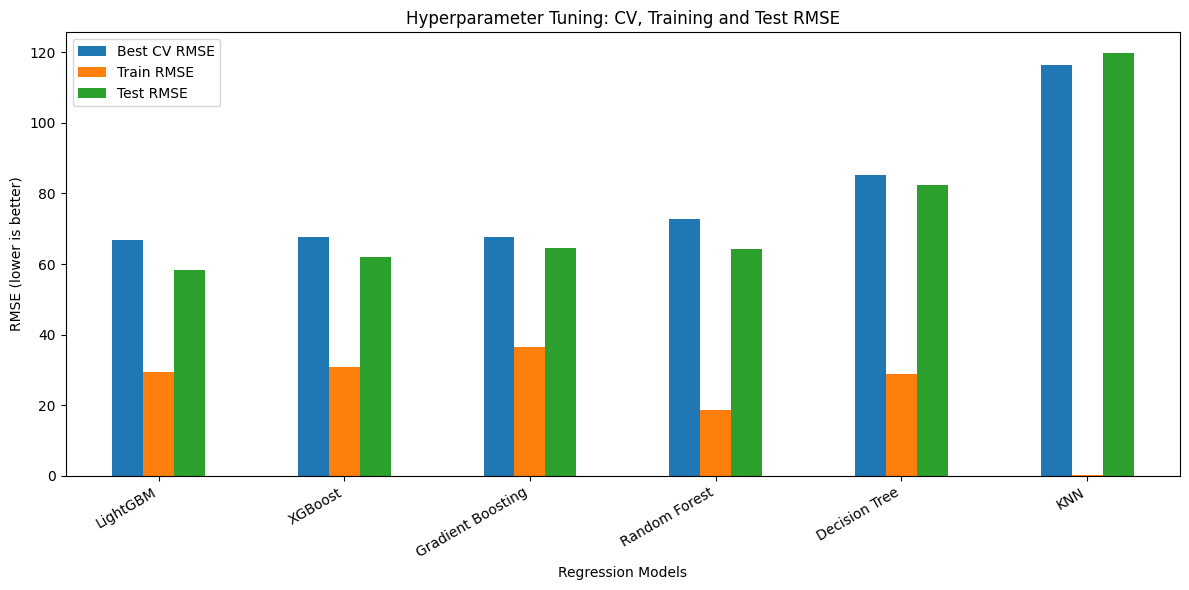

In [ ]:
# Compare CV, training and test RMSE
diagnostic_results = cv_results[['Model', 'Best CV RMSE']].merge(
    tuned_results[['Model', 'Train RMSE', 'Test RMSE', 'Generalization Gap']],
    on='Model'
)

display(diagnostic_results.sort_values('Test RMSE'))

# Visual comparison of errors
diagnostic_results.set_index('Model')[
    ['Best CV RMSE', 'Train RMSE', 'Test RMSE']
].plot(kind='bar', figsize=(12, 6))

plt.title('Hyperparameter Tuning: CV, Training and Test RMSE')
plt.ylabel('RMSE (lower is better)')
plt.xlabel('Regression Models')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

5.7 Select the best tuned model

In [ ]:
best_model_name = tuned_results.iloc[0]['Model']
best_model = best_models[best_model_name]

print("Best Model based on Test RMSE:", best_model_name)
print(f"Test RMSE: {tuned_results.iloc[0]['Test RMSE']:.4f}")
print(f"Test MAE: {tuned_results.iloc[0]['Test MAE']:.4f}")
print(f"Test R2 Score: {tuned_results.iloc[0]['Test R2']:.4f}")
print("\nBest Hyperparameters:")
print(searches[best_model_name].best_params_)

Best Model based on Test RMSE: LightGBM
Test RMSE: 58.3083
Test MAE: 37.4634
Test R2 Score: 0.8847

Best Hyperparameters:
{'subsample': 0.85, 'reg_lambda': 0, 'num_leaves': 31, 'n_estimators': 300, 'min_child_samples': 20, 'max_depth': 20, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


# 6. Model Evaluation

## 6.1 Evaluation Metrics for Regression Models

The trained regression models are evaluated using the unseen test data (`X_test` and `y_test`).

1. **Mean Absolute Error (MAE):** Average absolute difference between actual and predicted values. Lower MAE indicates better predictions.
2. **Mean Squared Error (MSE):** Average of squared prediction errors. It penalizes large errors more strongly. Lower MSE is better.
3. **Root Mean Squared Error (RMSE):** Square root of MSE. It is expressed in the same unit as the target variable (`cnt`). Lower RMSE is better.
4. **R-squared (R²):** Measures how much variation in the target variable is explained by the model. A value closer to 1 generally indicates a better fit.

The formulas are:

- MAE = mean(|actual − predicted|)
- MSE = mean((actual − predicted)²)
- RMSE = √MSE
- R² = 1 − (sum of squared residuals / total sum of squares)

## 6.2 Compare Model Performance and Select the Best Model

In [ ]:
# Import evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_squared_log_error,
    r2_score
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate every tuned model on the unseen test data
evaluation_results = []
evaluation_predictions = {}

for model_name, model in best_models.items():
    y_pred = model.predict(X_test)
    evaluation_predictions[model_name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    evaluation_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create a comparison table (lower errors and higher R2 are preferred)
evaluation_df = (
    pd.DataFrame(evaluation_results)
    .sort_values(by=["RMSE", "MAE"], ascending=[True, True])
    .reset_index(drop=True)
)

print("Regression Model Evaluation on Test Data")
display(evaluation_df.round(4))

Regression Model Evaluation on Test Data


,Model,MAE,MSE,RMSE,R2 Score
0,LightGBM,37.4634,3399.8574,58.3083,0.8847
1,XGBoost,40.1462,3856.9155,62.1041,0.8692
2,Random Forest,41.7566,4127.6548,64.2468,0.8600
3,Gradient Boosting,43.1482,4181.0640,64.6611,0.8582
4,Decision Tree,50.6482,6769.8584,82.2791,0.7703
5,KNN,84.2147,14323.8092,119.6821,0.5141


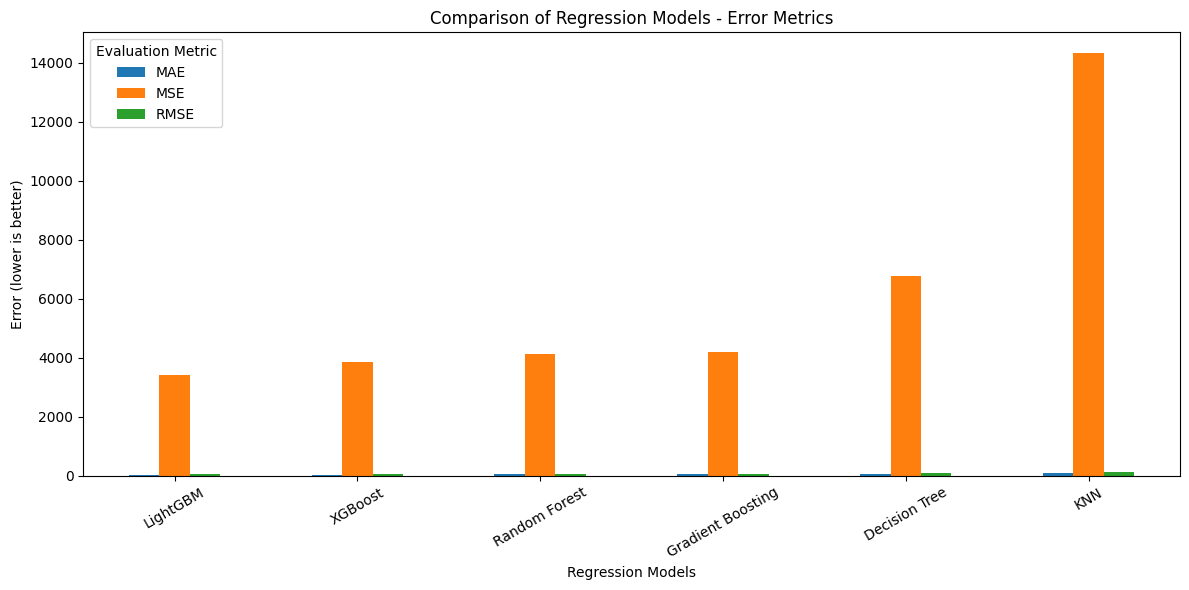

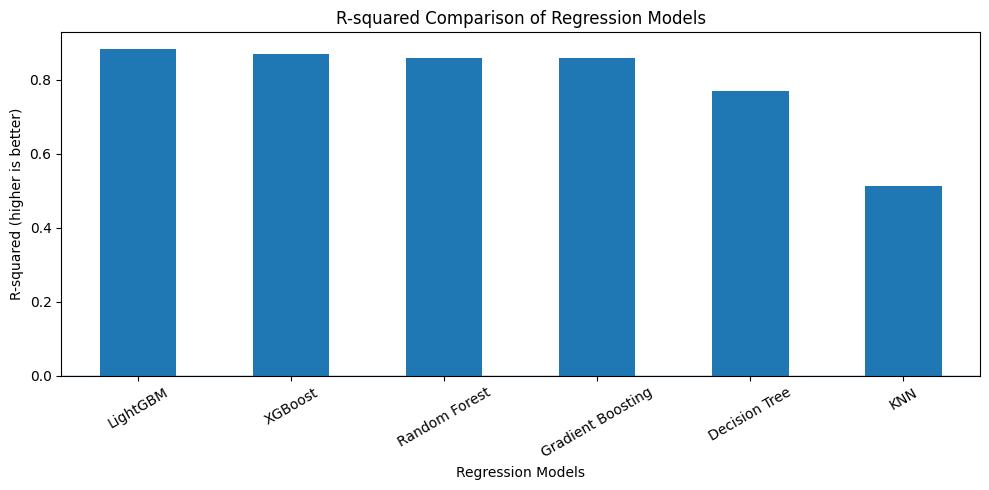

In [ ]:
# Compare error metrics visually
metric_columns = ["MAE", "MSE", "RMSE"]

evaluation_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(12, 6),
    rot=30
)
plt.title("Comparison of Regression Models - Error Metrics")
plt.xlabel("Regression Models")
plt.ylabel("Error (lower is better)")
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

# Compare R-squared scores separately because higher values are better
evaluation_df.set_index("Model")["R2 Score"].plot(
    kind="bar",
    figsize=(10, 5),
    rot=30
)
plt.title("R-squared Comparison of Regression Models")
plt.xlabel("Regression Models")
plt.ylabel("R-squared (higher is better)")
plt.axhline(0, linewidth=1)
plt.tight_layout()
plt.show()

In [ ]:
# Select the best model using the lowest test RMSE
best_evaluation = evaluation_df.iloc[0]
best_evaluation_model_name = best_evaluation["Model"]
best_evaluation_model = best_models[best_evaluation_model_name]

print("Best Regression Model:", best_evaluation_model_name)
print(f"MAE      : {best_evaluation['MAE']:.4f}")
print(f"MSE      : {best_evaluation['MSE']:.4f}")
print(f"RMSE     : {best_evaluation['RMSE']:.4f}")
print(f"R-squared: {best_evaluation['R2 Score']:.4f}")

print("\nConclusion:")
print(
    f"{best_evaluation_model_name} is selected as the best model because "
    "it has the lowest RMSE on the unseen test data. "
    "Its MAE, MSE and R-squared values are also shown above for a complete "
    "performance comparison."
)

Best Regression Model: LightGBM
MAE      : 37.4634
MSE      : 3399.8574
RMSE     : 58.3083
R-squared: 0.8847

Conclusion:
LightGBM is selected as the best model because it has the lowest RMSE on the unseen test data. Its MAE, MSE and R-squared values are also shown above for a complete performance comparison.
